<a href="https://colab.research.google.com/github/nuralfiyanti/ML_Ganjil2026/blob/main/JS09ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Nama : Nur Alfiyanti

NIM : 244107020055

Kelas : TI-3E

JS09 - Klasifikasi

## **Praktikum 1**

k-Nearest Neighbors (kNN)



**Langah 1 - Load Data**

In [56]:
	# Load data
	import pandas as pd
	data = pd.read_csv('iris (1).csv')
	data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


**Langkah 2 - Eksplorasi Data**

Cek struktur data informasi deskriptif data




In [57]:
	data.info()
	data.describe()
	data['species'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


,count
species,
setosa,50
versicolor,50
virginica,50


**Langkah 3 - Visualisasi Data**

Lakukan visualisasi data untuk mengetahui distribusi dan korelasi setiap fitur terhadap label.




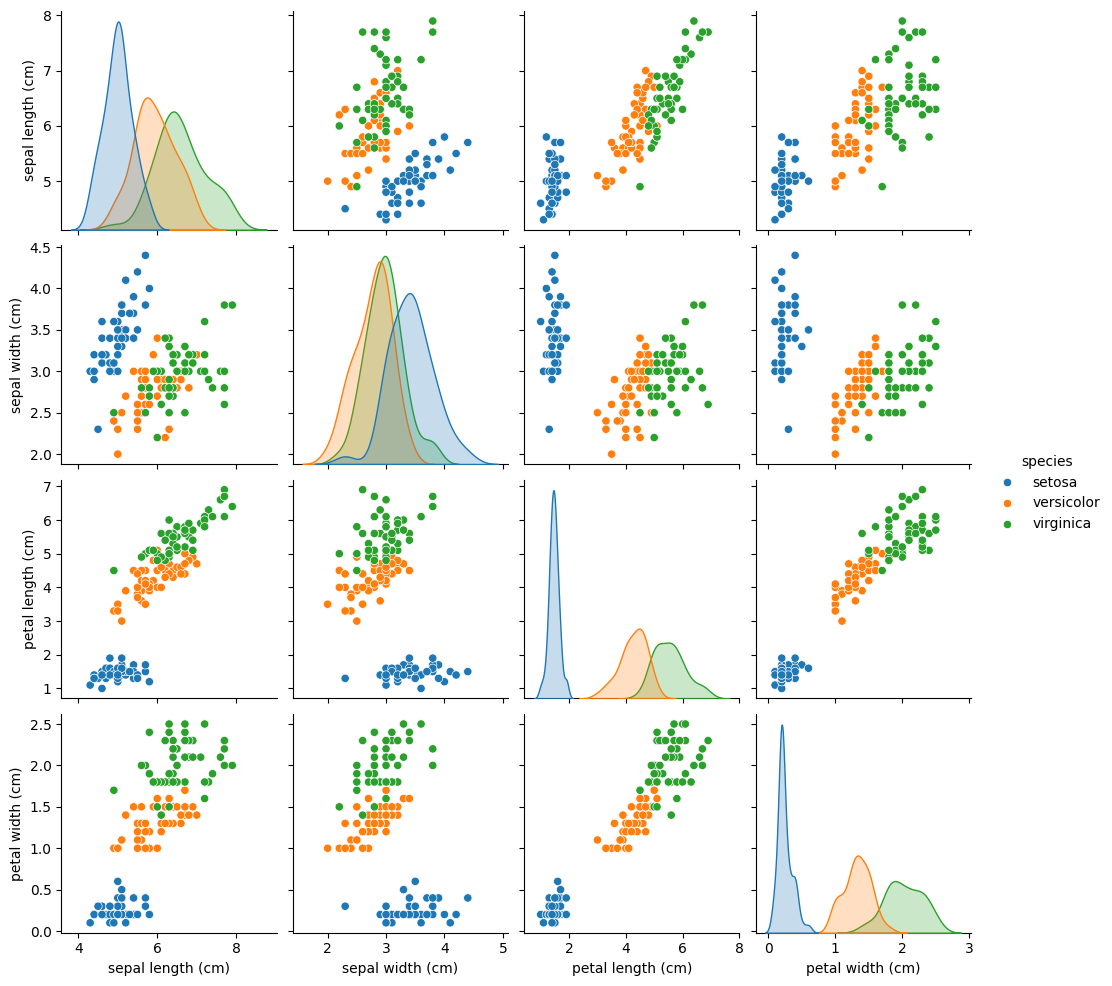

In [58]:
	import seaborn as sns
	import matplotlib.pyplot as plt

	sns.pairplot(data, hue='species')
	plt.show()

**Langkah 4 - Preprocessing**

Pada tahap ini, kita akan memisahkan antara label dengan fitur yang akan digunakan. Selain itu, untuk alasan pembelajaran, kita akan melakukan standardisasi dari fitur yang akan digunakan.


Pada kasus Iris Dataset, seluruh fitur sudah dalam satuan yang sama yaitu cm.

In [59]:
	from sklearn.model_selection import train_test_split
	from sklearn.preprocessing import StandardScaler

	X = data.iloc[:, :-1]   # semua kolom kecuali label
	y = data.iloc[:, -1]    # kolom label terakhir

	# Split data (70% train, 30% test)
	X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

	# Standardisasi
	scaler = StandardScaler()
	X_train = scaler.fit_transform(X_train)
	X_test = scaler.transform(X_test)

**Langkah 5 - Buat Model kNN**

In [60]:
	from sklearn.neighbors import KNeighborsClassifier

	# Tentukan nilai K (misalnya 3)
	knn = KNeighborsClassifier(n_neighbors=3)

	# Latih model
	knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

**Langkah 6 - Evaluasi Model kNN**

Pada tahap ini kita akan melakukan evaluasi terhadap model kNN yang telah dibuat sebelumnya. Metrik utama yang akan digunakan adalah akurasi dan detail analisis menggunakan confusion metrics.

In [61]:
	from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

	y_pred = knn.predict(X_test)
	print("Akurasi:", accuracy_score(y_test, y_pred))
	print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
	print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 1.0
Confusion Matrix:
 [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



Dapat dilihat bahwa model dapat bekerja dengan performa sempurna pada data testing. Namun apakah memang nilai
k
k adalah nilai yang terbaik? Selanjutnya kita akan mengevaluasi setiap nilai
k
k.

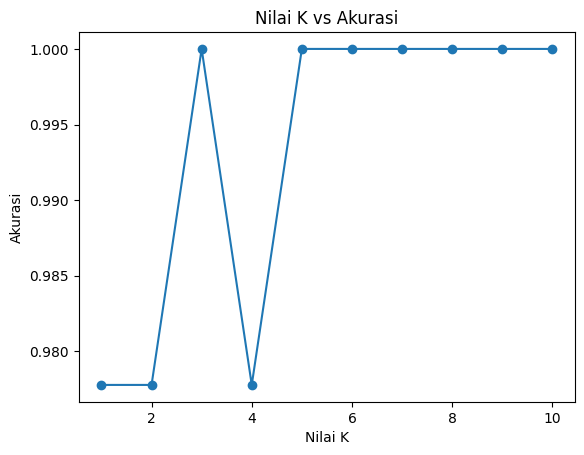

In [62]:
	acc = []
	for k in range(1, 11):
	    model = KNeighborsClassifier(n_neighbors=k)
	    model.fit(X_train, y_train)
	    acc.append(model.score(X_test, y_test))

	plt.plot(range(1, 11), acc, marker='o')
	plt.title('Nilai K vs Akurasi')
	plt.xlabel('Nilai K')
	plt.ylabel('Akurasi')
	plt.show()


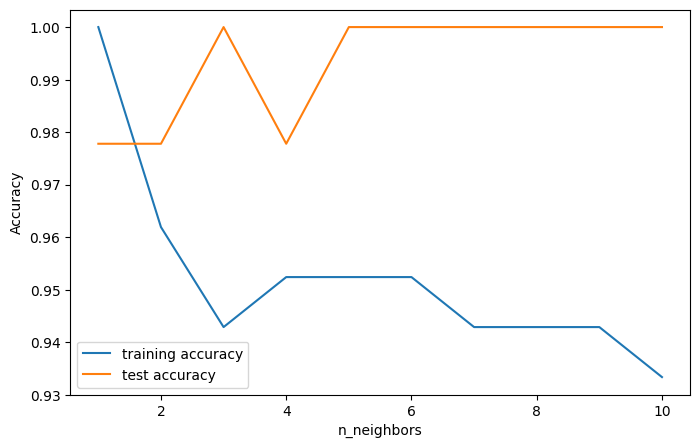

In [63]:
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

train_accuracy = []
test_accuracy = []

neighbors = range(1, 11)

for k in neighbors:
    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train, y_train)

    y_train_pred = knn.predict(X_train)
    y_test_pred = knn.predict(X_test)

    train_accuracy.append(accuracy_score(y_train, y_train_pred))
    test_accuracy.append(accuracy_score(y_test, y_test_pred))

plt.figure(figsize=(8, 5))

plt.plot(neighbors, train_accuracy, label="training accuracy")
plt.plot(neighbors, test_accuracy, label="test accuracy")

plt.xlabel("n_neighbors")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

## **Praktikum 2**

Pada percobaan ini kita akan menggunakan data dummy (sintentis) untuk membuat sebuah model Naive Bayes. Untuk membuat data dummy, kita dapat menggunakan fungsi make_classification dari library scikit-learn. Selanjutnya, kita akan membuat model Multinomial Naive Bayes dengan menggunakan MultinomialNB dan model Gaussian Naive Bayes menggunakan GaussianNB.

**Langkah 1 - Buat Dataset Dummy**


In [64]:
	import numpy as np
	from sklearn.datasets import make_classification

	# Membuat data dummy
	# Hasil dari make_classification berupa data fitur X dan label y
	# Label y akan berupa data yang sudah di encode (angka)
	X,y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2, n_redundant=0, n_repeated=0, shuffle=False)

	# Secara defalt, make_classfication menghasilkan nilai float
	# Kita perlu merubah dalam bentuk diskrit

	# Absolutekan nilai
	X = np.absolute(X)

	# Bulatkan nilai ke 2 angka dibelakang koma
	# Kalikan dengan 100 supaya tidak ada lagi koma
	X = np.round(X, 2) * 100

	# Ubah ke dalam bentuk integer
	X = X.astype(int)

	# Cek Hasil
	print(X)
	print(y)

[[108 245]
 [141  77]
 [ 62 123]
 [ 46 154]
 [ 52 144]
 [ 27 182]
 [ 91 258]
 [194  27]
 [216 211]
 [162 130]
 [ 61  59]
 [ 44  16]
 [ 47  33]
 [265 285]
 [ 47  71]
 [119 137]
 [ 91  11]
 [150 161]
 [ 83 138]
 [204  64]
 [ 28  48]
 [197 101]
 [ 41  98]
 [ 70  86]
 [128 101]
 [175 131]
 [143 118]
 [306 172]
 [194 120]
 [222 120]]
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


Parameter yang digunakan pada fungsi make_classification adalah,

`n_samples`: jumlah sampel yang diinginkan

`n_features`: jumlah fitur yang digunakan

`n_classes`: jumlah kelas

`n_informative`: jumlah fitur yang memiliki korelasi dengan kelas

`n_redundant`: jumlah fitur yang tidak memiliki korelasi dengan kelas

`n_repeated`: jumlah fitur yang diulang

**Langkah 2 (Opsional) - Membuat Data Frame**

Agar data lebih mudah untuk dibaca, maka kita akan membuat DataFrame dengan menggunakan library Pandas berdasarkan data dummy yang telah dibuat sebelumnya.




In [65]:
	import pandas as pd

	# Reshape label y menjadi 2D
	# Hal ini dilakukan karena kita akan menggabungkannya dengan data fitur X
	y_new = y.reshape(len(y), 1)

	# Gabungkan fitur X dan label y dalam data array
	data = np.concatenate((X, y_new), axis=1)

	# Definisikan nama kolom
	nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

	# Buat Data Frame
	df = pd.DataFrame(data, columns=nama_kolom)

	# Cek Data Frame
	df.head()

,Fitur 1,Fitur 2,Label
0,108,245,0
1,141,77,0
2,62,123,0
3,46,154,0
4,52,144,0


**Langkah 3 (Opsional) - Labeling**

 Dikarenakan label masih berbetuk encoding angka, untuk mempermudah pembacaan data, kita dapat mengubah bentuknya dalam bentuk kategorial




In [66]:
	# Definisikan nama label
	labels = {
	    1 : 'Kelas A',
	    0 : 'Kelas B'
	}

	# Copy Data Frame untuk menyimpan Data Frame baru
	# dengan label yang mudah untuk dibaca
	df_label = df.copy()

	# Ubah label dengan fungsi mapping dari Pandas
	# pada Data Frame df_label
	df_label['Label'] = df_label['Label'].map(labels)

	# Cek Data Frame df_label
	df_label.head()

,Fitur 1,Fitur 2,Label
0,108,245,Kelas B
1,141,77,Kelas B
2,62,123,Kelas B
3,46,154,Kelas B
4,52,144,Kelas B


**Langkah 4 - Visualisasi Data**

/tmp/ipykernel_3376/3164796497.py:11: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_a = gb.get_group('Kelas A')
/tmp/ipykernel_3376/3164796497.py:12: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_b = gb.get_group('Kelas B')


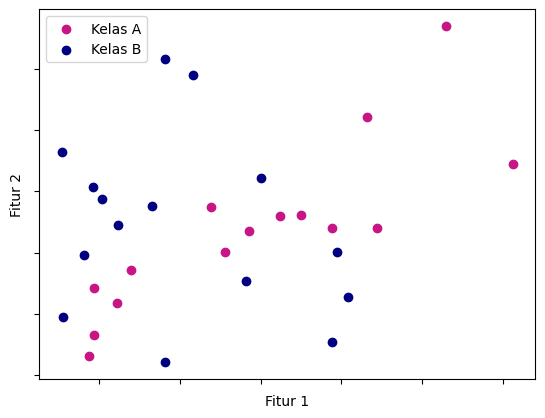

In [67]:
	import matplotlib.pyplot as plt

	# Definisikan warna untuk setiap kelas
	colors = {
	    'class_a': 'MediumVioletRed',
	    'class_b': 'Navy'
	}

	# Kelompokkan label berdasarkan nama kelas
	gb = df_label.groupby(['Label'])
	class_a = gb.get_group('Kelas A')
	class_b = gb.get_group('Kelas B')

	# Plot
	plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'])
	plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'])
	plt.xlabel('Fitur 1')
	plt.ylabel('Fitur 2')
	plt.legend(['Kelas A', 'Kelas B'])
	plt.gca().axes.xaxis.set_ticklabels([])
	plt.gca().axes.yaxis.set_ticklabels([])
	plt.show()

**Langkah 5 - Model Multinomial Naive Bayes**

Selanjutnya buat model naive bayes dengan jenis multinomoial. Sejatinya, **model multinomial digunakan untuk fitur yang bersifat diskrit** (e.g. jumlah kata untuk klasifikasi teks). Akan tetapi kita akan mencoba menggunakan model ini untuk konteks data kontinu **hanya sebagai pembelajaran**.

In [68]:
	from sklearn.naive_bayes import MultinomialNB # class untuk model MultinomialNB
	from sklearn.model_selection import train_test_split
	from sklearn.metrics import accuracy_score # evaluasi model berdasarkan akurasi

	# Inisiasi obyek MultinomialNB
	mnb = MultinomialNB()

	# Kita dapat langsung menggunakan fitur X dan label y
	# hasil dari proses pembuatan data dummy

	# Split data training dan testing
	X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=30)

	# Fit model
	# Label y harus dalam bentuk 1D atau (n_samples,)
	mnb.fit(X_train, y_train)

	# Prediksi dengan data training
	y_train_pred = mnb.predict(X_train)

	# Evaluasi akurasi training
	acc_train = accuracy_score(y_train, y_train_pred)

	# Prediksi test data
	y_test_pred = mnb.predict(X_test)

	# Evaluasi model dengan metric akurasi
	acc_test = accuracy_score(y_test, y_test_pred)

	# Print hasil evaluasi
	print(f'Hasil akurasi data train: {acc_train}')
	print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.6190476190476191
Hasil akurasi data test: 0.6666666666666666


**Langkah 6 - Model Gaussian Naive Bayes**

Model Gaussian lebih cocok digunakan untuk data kontinu yang kita miliki, hal ini dikarenakan model ini menggunakan distribusi gaussian (normal) yang secara alami memiliki rentang dengan nilai kontinu.

In [69]:
	from sklearn.naive_bayes import GaussianNB # class untuk model GaussianNB

	# Inisiasi obyek Gaussian
	gnb = GaussianNB()

	# Kita menggunakan split data training dan testing
	# yang sama dengan model multinomial

	# Fit model
	# Label y harus dalam bentu 1D atau (n_samples,)
	gnb.fit(X_train, y_train)

	# Prediksi dengan data training
	y_train_pred_gnb = gnb.predict(X_train)

	# Evaluasi akurasi training
	acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

	# Prediksi test data
	y_test_pred_gnb = gnb.predict(X_test)

	# Evaluasi model dengan metric akurasi
	acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

	# Print hasil evaluasi
	print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
	print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.7142857142857143
Hasil akurasi data test (Gaussian): 0.1111111111111111


Meskipun hasilnya tidak jauh berbeda dengan model multimodal, secara teoritis kita telah menerapkan langkah yang benar dalam membuat sebuah model klasifikasi dengan menggunakan Naive Bayes.

## **Praktikum 3**

Klasifikasi Naive Bayes dengan Data Multimoda



**Intro**

Pada percobaan ini, kita akan menggunakan nilai multinomial untuk melakukan klasifikasi dengan Naive Bayes. Nilai multinomial adalah data yang nilainya didapatkan dari proses menghitung. Sehingga, pada konteks fitur, nilai multinomial fitur berdasarkan proses perhitungan (counting) probabilitas kemunculan fitur tersebut dalam sebuah data. Contoh klasik fitur multinomial adalah perhitungan jumlah kata pada klasifikasi teks.Pada percobaan ini, kasus klasifikasi teks diberikan untuk mempermudah pemahaman terhadap algoritma Naive Bayes tipe Multinomial.

Kita akan menggunakan data spam.csv yang berisi data teks sms dengan label **spam** dan **ham**. Spam adalah sms sampah, sedangkan ham adalah sebaliknya.

**Langkah 1 - Load Data**

Pada tahap ini kita akan loading data ke dalam data frame dan melakukan inspeksi sederhana untuk memastikan apakah kita perlu proses pra pengolahan data sebelum melakukan ekstraksi fitur dan permodelan.

In [70]:
	import numpy as np
	import pandas as pd

	df = pd.read_csv('spam.csv', encoding='latin-1') # spesifiksi encoding diperlukan karena data tidak menggunakan UTF-8

	df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


Terdapat 3 kolom yang tidak bermanfaat untuk proses selanjutnya, maka kita perlu membuang kolom tersebut. Selain itu, untuk memudahkan pembacaan data, kita juga akan mengubah nama kolom v1 yang berupa label dan v2 yang berupa teks sms.

**Langkah 2 - Preprocessing**



Beberapa hal yang akan dilakukan pada tahap ini yaitu,

1. Drop kolom yang tidak digunakan

2. Ubah nama kolom v1 (label) dan v2 (teks sms)

3. Inspeksi Data

4. Encode label

5. Memisahkan fitur dengan label

**Langkah 2a - Drop Kolom**



In [71]:
	# Drop 3 kolom terakhir dengan fungsi iloc
	df = df.drop(df.iloc[:,2:], axis=1)

	# Cek data
	df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


**Langkah 2b - Inspeksi Data**


In [84]:
print(df.columns)
df.head()

Index(['Labels', 'SMS'], dtype='object')


,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [73]:

# Cek Jumlah Data Per Kelas
print("Jumlah Data:")
print(df.shape[0])
print('\n')

# Cek Kelengkapan Data
print(df.info())
print('\n')

# Cek Statistik Deskriptif
print(df.describe())

Jumlah Data:
5572


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   v1      5572 non-null   object
 1   v2      5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None


          v1                      v2
count   5572                    5572
unique     2                    5169
top      ham  Sorry, I'll call later
freq    4825                      30


**Langkah 2c - Encoding Label**

In [80]:
# Data untuk label
new_labels = {
    'spam': 1,
    'ham': 0
}

# Encode label
df['Labels'] = df['Labels'].map(new_labels)

# Cek data
df.head()

,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


**Langkah 2d - Pisahkan Fitur dengan Label**

In [81]:
	X = df['SMS'].values
	y = df['Labels'].values

**Langkah 3 - Ekstraksi Fitur**

Ekstraksi fitur untuk setiap SMS akan menggunakan konsep Bag of Words. Kita dapat menggunakan fungsi CountVectorizer dari scikit-learn. Akan tetapi untuk mencegah leaking information kita akan melakukan split data terlebih dahulu, baru melakukan transformasi terhadap data training dan testing.

In [82]:
	from sklearn.model_selection import train_test_split
	from sklearn.feature_extraction.text import CountVectorizer

	# Split data training dan testing
	X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)

	# Inisiasi CountVectorizer
	bow = CountVectorizer()

	# Fitting dan transform X_train dengan CountVectorizer
	X_train = bow.fit_transform(X_train)

	# Transform X_test
	# Mengapa hanya transform? Alasan yang sama dengan kasus pada percobaan ke-3
	# Kita tidak menginginkan model mengetahui paramter yang digunakan oleh CountVectorizer untuk fitting data X_train
	# Sehingga, data testing dapat tetap menjadi data yang asing bagi model nantinya
	X_test = bow.transform(X_test)

Cek fitur dari proses `CountVectorizer`.

In [86]:
print(len(bow.get_feature_names_out()))
print(f'Dimensi data: {X_train.shape}')

7727
Dimensi data: (4457, 7727)


**Langkah 4 - Training dan Evaluasi Model**

Kita akan menggunakan algoritma Multinomial Naive Bayes. Fungsi MultinomialNB dari scikit-learn dapat digunakan pada kasus ini.




In [88]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

# Inisiasi MultinomialNB
mnb = MultinomialNB()

# Fit model
mnb.fit(X_train, y_train)

# Prediksi dengan data training
y_pred_train = mnb.predict(X_train)

# Evaluasi akurasi data training
acc_train = accuracy_score(y_train, y_pred_train)

# Prediksi dengan data testing
y_pred_test = mnb.predict(X_test)

# Evaluasi akurasi data testing
acc_test = accuracy_score(y_test, y_pred_test)

# Print hasil evaluasi
print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.9946152120260264
Hasil akurasi data test: 0.9775784753363229


## **Tugas 1**

**1. Buatlah model klasifikasi dengan menggunakan kNN untuk mengklasifikasikan jenis suara male dan female pada dataset voice.csv.**

**1.1 Load Data**

Upload `voice.csv` ke Colab (panel Files di kiri) terlebih dahulu.

In [89]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

voice = pd.read_csv('voice.csv')
print("Ukuran data :", voice.shape)
print("Missing     :", voice.isnull().sum().sum())
print(voice['label'].value_counts())
voice.head()

Ukuran data : (3168, 21)
Missing     : 0
label
male      1584
female    1584
Name: count, dtype: int64


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


**1.2 Persiapan Data**

Label di-encode (`male`=1, `female`=0), lalu data dibagi 80% training dan 20% testing dengan `stratify` agar proporsi male/female tetap seimbang. Karena kNN berbasis jarak, fitur **wajib di-scale**. Scaling dimasukkan ke dalam `pipeline` agar tidak terjadi data leakage.

In [90]:
X = voice.drop(columns='label')
y = voice['label'].map({'male': 1, 'female': 0})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Model dasar: semua fitur, k=5
base = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
base.fit(X_train, y_train)
print("Akurasi test (20 fitur, k=5):", round(accuracy_score(y_test, base.predict(X_test)), 4))

Akurasi test (20 fitur, k=5): 0.9763


**2.Lakukan percobaan untuk mengetahui fitur-fitur yang paling optimal untuk digunakan. Fitur apa saja yang Anda gunakan untuk mendapatkan hasil terbaik?**

**1.3 Mencari Fitur Optimal**

Langkah: (a) ranking fitur dengan uji ANOVA F-score, (b) mencoba memakai 1, 2, ..., 20 fitur teratas, dan setiap jumlah fitur dievaluasi dengan 5-fold cross-validation pada data training.

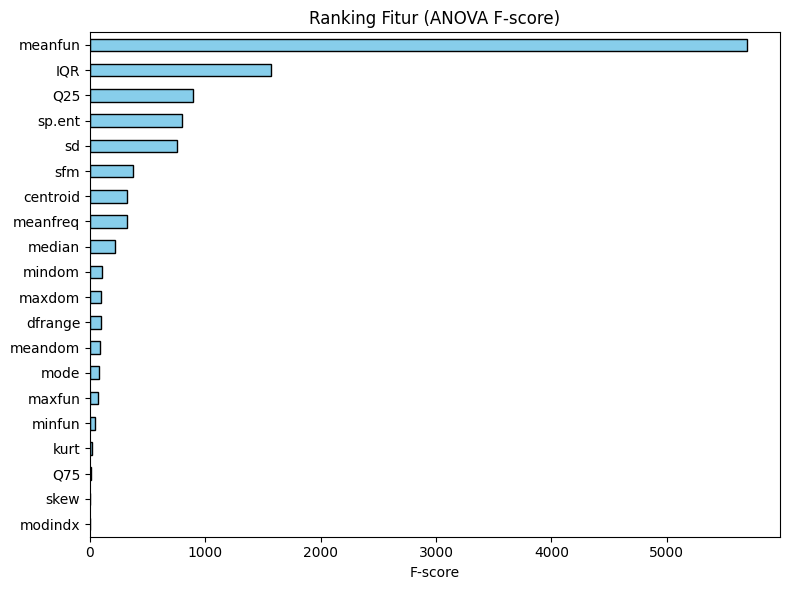

meanfun     5697.9
IQR         1566.5
Q25          890.4
sp.ent       794.1
sd           750.8
sfm          375.2
centroid     324.4
meanfreq     324.4
median       218.3
mindom       100.4
maxdom        96.5
dfrange       93.0
meandom       89.2
mode          76.1
maxfun        69.7
minfun        47.4
kurt          19.3
Q75           11.3
skew           3.8
modindx        2.1
dtype: float64


In [91]:
# (a) Ranking fitur
skor = SelectKBest(f_classif, k='all').fit(X_train, y_train)
ranking = pd.Series(skor.scores_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
ranking.sort_values().plot(kind='barh', color='skyblue', edgecolor='k')
plt.title("Ranking Fitur (ANOVA F-score)")
plt.xlabel("F-score")
plt.tight_layout()
plt.show()
print(ranking.round(1))

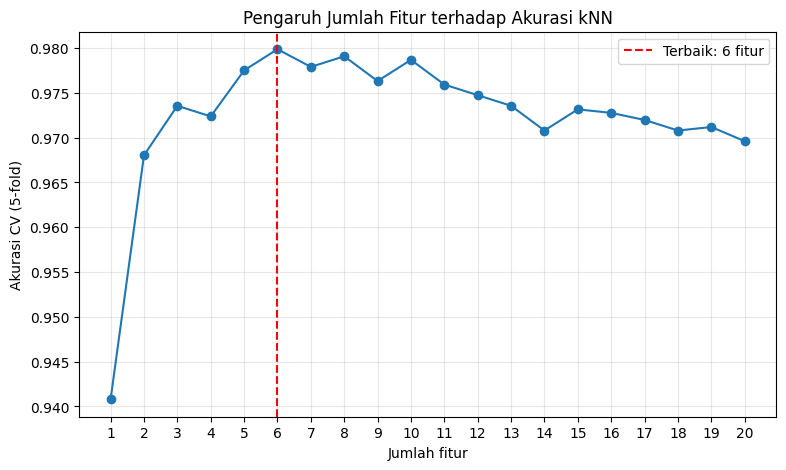

Jumlah fitur terbaik : 6
Akurasi CV           : 0.9799 (semua 20 fitur: 0.9696)
Fitur terpilih       : ['sd', 'Q25', 'IQR', 'sp.ent', 'sfm', 'meanfun']


In [92]:
# (b) Akurasi CV untuk berbagai jumlah fitur (k tetangga = 5)
n_fitur = range(1, X.shape[1] + 1)
acc_cv = []
for n in n_fitur:
    pipe = make_pipeline(StandardScaler(), SelectKBest(f_classif, k=n), KNeighborsClassifier(n_neighbors=5))
    acc_cv.append(cross_val_score(pipe, X_train, y_train, cv=cv).mean())

best_n = int(np.argmax(acc_cv)) + 1
plt.figure(figsize=(9, 5))
plt.plot(n_fitur, acc_cv, marker='o')
plt.axvline(best_n, color='r', linestyle='--', label=f'Terbaik: {best_n} fitur')
plt.xticks(list(n_fitur))
plt.xlabel("Jumlah fitur")
plt.ylabel("Akurasi CV (5-fold)")
plt.title("Pengaruh Jumlah Fitur terhadap Akurasi kNN")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

selector = SelectKBest(f_classif, k=best_n).fit(X_train, y_train)
fitur_terpilih = list(X.columns[selector.get_support()])
print(f"Jumlah fitur terbaik : {best_n}")
print(f"Akurasi CV           : {acc_cv[best_n-1]:.4f} (semua 20 fitur: {acc_cv[-1]:.4f})")
print("Fitur terpilih       :", fitur_terpilih)

**3. Berdasarkan fitur yang telah Anda pilih pada soal nomor 2, berapa nilai  yang terbaik? Lampirkan grafika analisis dan alasan Anda.**

**1.4 Mencari Nilai k Terbaik**

Dengan fitur terpilih, nilai `k` (n_neighbors) dicoba dari 1 sampai 30 dan dievaluasi dengan 5-fold cross-validation.

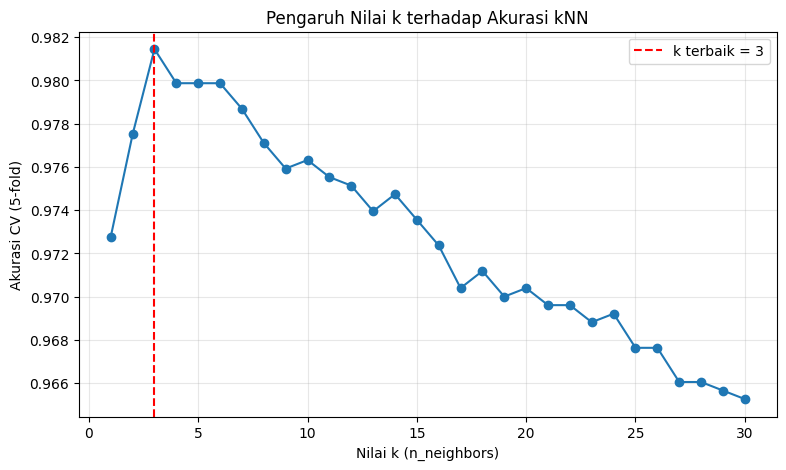

k terbaik: 3 dengan akurasi CV 0.9814


In [93]:
X_train_sel = X_train[fitur_terpilih]
X_test_sel = X_test[fitur_terpilih]

k_values = range(1, 31)
acc_k = []
for k in k_values:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    acc_k.append(cross_val_score(pipe, X_train_sel, y_train, cv=cv).mean())

best_k = int(np.argmax(acc_k)) + 1
plt.figure(figsize=(9, 5))
plt.plot(k_values, acc_k, marker='o')
plt.axvline(best_k, color='r', linestyle='--', label=f'k terbaik = {best_k}')
plt.xlabel("Nilai k (n_neighbors)")
plt.ylabel("Akurasi CV (5-fold)")
plt.title("Pengaruh Nilai k terhadap Akurasi kNN")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print(f"k terbaik: {best_k} dengan akurasi CV {acc_k[best_k-1]:.4f}")

**1.5 Evaluasi Akhir pada Data Test**

Akurasi test : 0.9874
              precision    recall  f1-score   support

      female       0.99      0.99      0.99       317
        male       0.99      0.99      0.99       317

    accuracy                           0.99       634
   macro avg       0.99      0.99      0.99       634
weighted avg       0.99      0.99      0.99       634



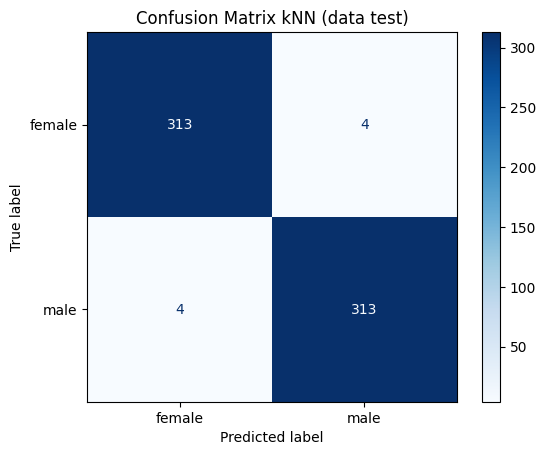

In [94]:
final = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
final.fit(X_train_sel, y_train)
y_pred = final.predict(X_test_sel)

print("Akurasi test :", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=['female', 'male']))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['female', 'male'], cmap='Blues')
plt.title("Confusion Matrix kNN (data test)")
plt.show()

**1.6 Analisis Tugas 1**

Soal 2 - Fitur optimal. Dari ranking F-score, fitur yang paling berpengaruh adalah meanfun. Akurasi cross-validation tertinggi diperoleh dengan 6 fitur (0.9799), dibandingkan 0.9696 jika memakai seluruh 20 fitur. Fitur terpilih: ['sd', 'Q25', 'IQR', 'sp.ent', 'sfm', 'meanfun']. Artinya, menambah fitur yang kurang relevan justru menurunkan akurasi, karena pada kNN setiap fitur ikut menentukan jarak sehingga fitur yang kurang informatif menambah noise.

Soal 3 - Nilai k terbaik. Berdasarkan grafik, nilai k = 3 memberikan akurasi CV tertinggi (0.9814). Nilai k yang terlalu kecil membuat model sensitif terhadap noise (overfitting), sedangkan k yang terlalu besar membuat batas keputusan terlalu halus (underfitting). Pada k terbaik, akurasi pada data test adalah 0.9874.

## **Tugas 2**


**Buatlah model klasfikasi Multinomial Naive Bayes dengan ketentuan,**

**- Menggunakan data spam.csv**

**- Fitur CountVectorizer dengan mengaktifkan stop_words**

**- Evaluasi hasilnya**



**2.1 Load dan Persiapan Data**

Split memakai `test_size=0.2` dan `random_state=50`, sama seperti Praktikum 3, supaya hasilnya bisa dibandingkan. (Kalau di notebook Praktikum 3 kamu sudah punya `df` dengan kolom `Labels` dan `SMS`, boleh dipakai langsung.)

In [95]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

df_spam = pd.read_csv('spam.csv', encoding='latin-1')[['v1', 'v2']]
df_spam.columns = ['Labels', 'SMS']
df_spam['Labels'] = df_spam['Labels'].map({'spam': 1, 'ham': 0})

Xs = df_spam['SMS'].values
ys = df_spam['Labels'].values
Xs_train, Xs_test, ys_train, ys_test = train_test_split(Xs, ys, test_size=0.2, random_state=50)
print("Data train:", len(Xs_train), "| Data test:", len(Xs_test))

Data train: 4457 | Data test: 1115


**2.2 Fungsi Evaluasi**

Satu fungsi dipakai untuk semua eksperimen agar perbandingannya adil. Metrik **precision, recall, dan F1** dihitung untuk kelas **spam**, karena akurasi saja bisa menyesatkan pada data yang tidak seimbang (ham jauh lebih banyak dari spam).

In [96]:
hasil = []

def evaluasi(vectorizer, nama):
    Xv_train = vectorizer.fit_transform(Xs_train)
    Xv_test = vectorizer.transform(Xs_test)

    mnb = MultinomialNB().fit(Xv_train, ys_train)
    pred_train = mnb.predict(Xv_train)
    pred_test = mnb.predict(Xv_test)

    hasil.append({
        'Model': nama,
        'Jumlah fitur': Xv_train.shape[1],
        'Akurasi train': accuracy_score(ys_train, pred_train),
        'Akurasi test': accuracy_score(ys_test, pred_test),
        'Precision (spam)': precision_score(ys_test, pred_test),
        'Recall (spam)': recall_score(ys_test, pred_test),
        'F1 (spam)': f1_score(ys_test, pred_test),
    })

    print(f"=== {nama} ===")
    print("Jumlah fitur:", Xv_train.shape[1])
    print("Akurasi train:", round(accuracy_score(ys_train, pred_train), 4))
    print("Akurasi test :", round(accuracy_score(ys_test, pred_test), 4))
    print(classification_report(ys_test, pred_test, target_names=['ham', 'spam']))
    ConfusionMatrixDisplay.from_predictions(ys_test, pred_test, display_labels=['ham', 'spam'], cmap='Blues')
    plt.title(nama)
    plt.show()

**2.3 Eksperimen A - CountVectorizer dengan `stop_words`**

=== CountVectorizer + stop_words ===
Jumlah fitur: 7466
Akurasi train: 0.9946
Akurasi test : 0.983
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       954
        spam       0.98      0.90      0.94       161

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



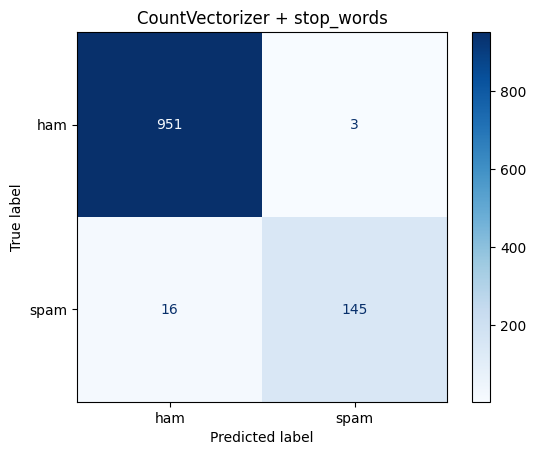

In [97]:
evaluasi(CountVectorizer(stop_words='english'), "CountVectorizer + stop_words")

**2.4 Eksperimen B - TF-IDF dengan `stop_words`**

=== TF-IDF + stop_words ===
Jumlah fitur: 7466
Akurasi train: 0.9843
Akurasi test : 0.9605
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       954
        spam       1.00      0.73      0.84       161

    accuracy                           0.96      1115
   macro avg       0.98      0.86      0.91      1115
weighted avg       0.96      0.96      0.96      1115



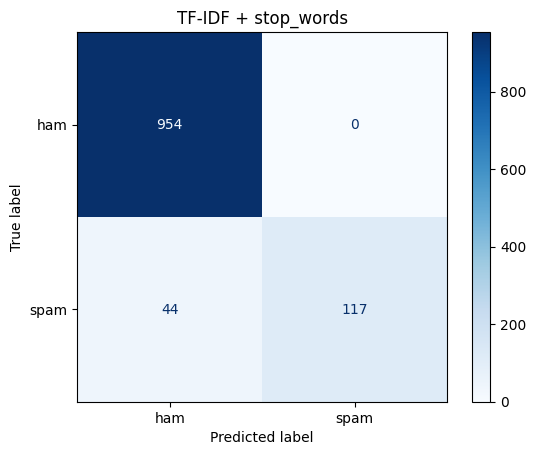

In [98]:
evaluasi(TfidfVectorizer(stop_words='english'), "TF-IDF + stop_words")

**2.5 Pembanding Tambahan: CountVectorizer tanpa `stop_words`**

Ini model dari Praktikum 3, dipakai untuk melihat apakah `stop_words` benar-benar berpengaruh.

=== CountVectorizer (tanpa stop_words) ===
Jumlah fitur: 7727
Akurasi train: 0.9946
Akurasi test : 0.9776
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       954
        spam       0.98      0.86      0.92       161

    accuracy                           0.98      1115
   macro avg       0.98      0.93      0.95      1115
weighted avg       0.98      0.98      0.98      1115



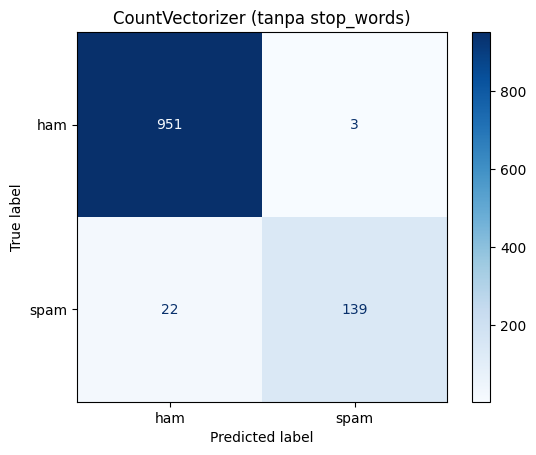

In [99]:
evaluasi(CountVectorizer(), "CountVectorizer (tanpa stop_words)")

**2.6 Perbandingan Hasil**

,Jumlah fitur,Akurasi train,Akurasi test,Precision (spam),Recall (spam),F1 (spam)
Model,,,,,,
CountVectorizer + stop_words,7466,0.9946,0.9830,0.9797,0.9006,0.9385
TF-IDF + stop_words,7466,0.9843,0.9605,1.0000,0.7267,0.8417
CountVectorizer (tanpa stop_words),7727,0.9946,0.9776,0.9789,0.8634,0.9175


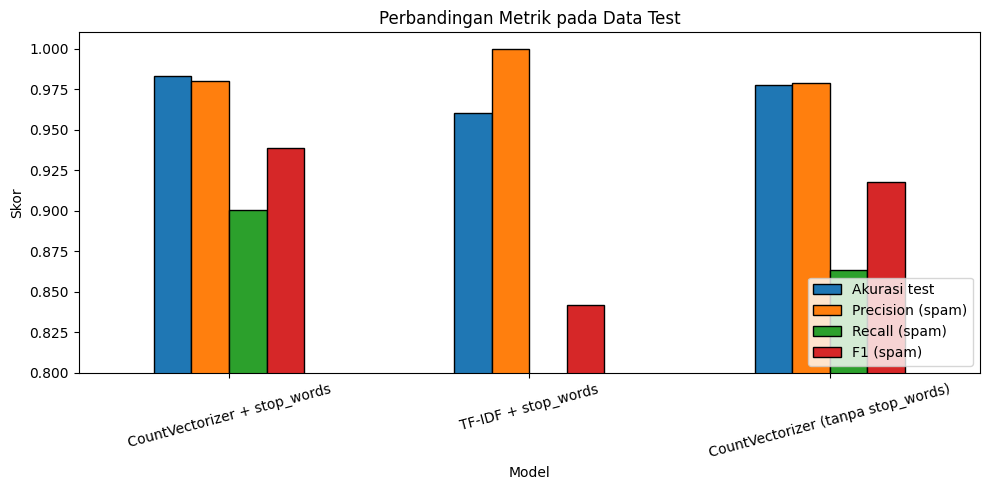

Fitur terbaik (berdasarkan F1 spam): CountVectorizer + stop_words


In [100]:
tabel = pd.DataFrame(hasil).set_index('Model').round(4)
display(tabel)

tabel[['Akurasi test', 'Precision (spam)', 'Recall (spam)', 'F1 (spam)']].plot(
    kind='bar', figsize=(10, 5), edgecolor='k')
plt.title("Perbandingan Metrik pada Data Test")
plt.ylabel("Skor")
plt.xticks(rotation=15)
plt.ylim(0.8, 1.01)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

terbaik = tabel.loc[['CountVectorizer + stop_words', 'TF-IDF + stop_words'], 'F1 (spam)'].idxmax()
print("Fitur terbaik (berdasarkan F1 spam):", terbaik)

**2.7 Analisis dan Kesimpulan Tugas 2**

**Evaluasi CountVectorizer + stop_words.** Akurasi test 0.9830, precision spam 0.9797, recall spam 0.9006. Dibandingkan model tanpa stop_words (akurasi test 0.9776), penggunaan stop_words menaikkan performa.

**Evaluasi TF-IDF + stop_words.** Akurasi test 0.9605, precision spam 1.0000, recall spam 0.7267.

**Perbandingan.** Dibandingkan dengan CountVectorizer, TF-IDF lebih buruk terutama pada metrik recall / F1 (meskipun precision mencapai sempurna 1.0000). Perbedaan tersebut terjadi karena CountVectorizer memakai jumlah kemunculan kata, sedangkan TF-IDF memberi bobot lebih kecil pada kata yang muncul di banyak dokumen. Pada Naive Bayes multinomial, bobot pecahan TF-IDF mengubah cara model menghitung probabilitas kata.

**Kesimpulan.** Pada data spam.csv, fitur yang terbaik adalah CountVectorizer + stop_words karena menghasilkan F1 tertinggi (0.9385). Pada kasus spam, recall kelas spam penting karena menunjukkan seberapa banyak spam yang berhasil terdeteksi, sedangkan precision menunjukkan berapa banyak SMS normal yang salah dianggap spam.